# 뉴런을 읽기 ③ — 조금만 남겨도 되나: 주장 1을 다른 모델에서 재기

논문의 첫 주장은 이것이다.

> 층마다 token마다 활성이 가장 센 뉴런 320개(4,096개 중 7.8%)만 남기고 나머지를 down projection 직전에 0으로 바꿔도, 모델은 웹 문서 손실이 +2.9% 늘 뿐이고 여러 벤치마크에서 원래 모델에 가깝다. 약한 활성(뉴런마다 분위수 p3–p97 사이)을 평균으로 바꿔도 비슷하다.

이 주장이 참이면, 뉴런을 해석할 때 **강한 활성만 보면 된다**. 논문의 주장 2, 3(뉴런마다 역할이 몇 개뿐이고 글로 설명할 수 있다)이 모두 p97/3 바깥의 강한 활성에서만 시험된 이유가 이것이다. 그래서 주장 1이 무너지면 뒤의 주장들은 범위가 줄어든다.

이 권은 같은 실험을 **다른 모델**(Qwen3-0.6B-Base, 작고 MoE가 아닌 dense 모델)에서 다시 하고, 논문 숫자를 볼 때 물어야 할 대조군 셋을 직접 돌린다.

1. 무작위로 같은 수를 남기면 얼마인가.
2. 끈 뉴런을 무엇으로 바꿨나(0인가 평균인가). 평균은 어떻게 쟀나.
3. "+2.9%가 작다"는 것은 무엇과 비교해서인가.

## 학습 목표, 필수 경로, stop rule

1. top-K 마스킹과 분위수 띠 마스킹을 식으로 정의하고 구현한다.
2. 남기는 비율 $K/F$에 따른 손실 곡선을 그리고, 같은 비율의 무작위 대조군과 비교한다.
3. 끄는 값(0, 평균)과 그 평균을 잰 방식이 결과를 얼마나 바꾸는지 본다. 여기서 이 권의 조용한 버그가 나온다.
4. ①의 크기 대칭 질문(|a| 기준과 쓰기 크기 기준은 같은 뉴런을 고르나)에 답한다.

**필수 경로:** Cell 01–07. CPU로 약 15분(마스킹 조건 하나에 약 50초). 오래 걸리는 셀은 머리에 적었다.

### ④로 넘어가도 되는 기준 (stop rule)

- "320개만 남겨도 손실 +2.9%"를 보고 물어야 할 대조군 셋(무작위 $K$개, 끄는 값과 그 평균의 출처, 무엇과 비교해 작다는 것인가)을 대고, 각각이 이 모델에서 어떻게 나왔는지 말할 수 있다.
- 주장 1이 이 모델에서 **어떤 형태로** 살아남는지 한 문장으로 쓸 수 있다(무엇은 옮겨 오고 무엇은 옮겨 오지 않았나).

표시는 ①②와 같다.

## 공통 setup

#### Cell 01 · 실행 환경, 모델, 데이터

- **이번 셀의 질문:** 환경이 같은가? 어떤 문서로 재는가?
- **출력에서 볼 것:** 버전, 평가 조각과 보정 조각의 크기, 문서 앞부분.
- **해석 범위:** 평가는 wikitext-103 test, 보정(평균과 분위수)은 validation에서 한다. 둘은 겹치지 않는다. 128 token 조각 64개씩, 각 8,192 token이다. 논문의 웹 문서(FineWeb 계열)보다 백과사전 문체에 치우친다.

In [1]:
import sys
from importlib.metadata import version
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "neuron_lab.py").exists():
    HERE = next(p for p in [HERE / "chapter1_transformer_interp/exercises/part35_neurons_ko", *HERE.parents]
                if (p / "neuron_lab.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import torch

import neuron_lab as nl
nl.pl.use_style()
print("torch", torch.__version__, "| transformers", version("transformers"))
model, tok = nl.load_model()
L, F = model.config.num_hidden_layers, model.config.intermediate_size
EVAL = nl.wikitext_chunks(tok, "test", 64)
CALIB = nl.wikitext_chunks(tok, "validation", 64)
print(f"평가 {tuple(EVAL.shape)}, 보정 {tuple(CALIB.shape)}, 층 {L}, 층마다 뉴런 {F}")
print("평가 첫 조각:", repr(tok.decode(EVAL[0, :40])))

torch 2.15.0+cpu | transformers 5.23.0


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


평가 (64, 128), 보정 (64, 128), 층 28, 층마다 뉴런 3072
평가 첫 조각: ' Robert Boulter is an English film , television and theatre actor . He had a guest @-@ starring role on the television series The Bill in 2000 . This was followed by'


## 1. 무엇을 재는가

[정의] **top-K 마스킹.** 층 $\ell$, 위치 $t$마다 활성 벡터 $a\in\mathbb{R}^F$에서 $|a_i|$ 상위 $K$개만 남기고 나머지를 0(또는 평균)으로 바꾼 뒤 $W_{\text{down}}$에 넣는다. **모든 층에 동시에** 건다. 마스크는 그 token 자신의 활성으로 매번 정하므로 학습이 필요 없다.

[정의] **분위수 띠 마스킹.** 뉴런마다 보정 데이터에서 활성 분포의 분위수를 잰다. 활성이 p10과 p90 사이(또는 p3과 p97 사이)면 약하다고 보고 그 뉴런의 평균으로 바꾼다. 남는 비율은 token마다 다르다.

[정의] **손실**: 다음 token의 평균 cross-entropy(nats). **KL**: 원래 모델의 다음 token 분포에서 바꾼 모델의 분포로의 KL divergence, token 평균. 손실은 정답 token 하나만 보고, KL은 분포 전체를 본다.

[근사] 논문과 다른 점. 논문 모델은 MoE라서 token마다 전문가 8개의 뉴런 4,096개만 켜지고, 그중 router weight를 곱한 활성으로 상위 320개를 고른다. 이 모델은 dense라서 3,072개가 모두 켜져 있고 router weight가 없다. 그래서 "7.8%"는 같은 비율이지만 같은 조건은 아니다.

## 2. 평균을 어디서 재나: 첫 위치

평균으로 바꾸려면 뉴런마다 평균 활성이 필요하다. 보정 조각에서 위치를 골라 잰다. 그런데 조각의 **첫 위치**는 앞 문맥이 없다. 많은 언어모델은 첫 위치에서 다른 위치와 크게 다른 활성을 낸다(attention sink와 관련된 현상).

**✍️ 예측 1.** 층마다 첫 위치의 $\max|a|$와 나머지 위치의 $\max|a|$를 비교한다. 비슷할까, 어느 층에서 크게 다를까? 그리고 첫 위치를 넣고 잰 평균과 빼고 잰 평균으로 각각 채우면, 7.8% top-K의 손실이 얼마나 다를까?

#### Cell 02 · 첫 위치의 활성

- **이번 셀의 질문:** 첫 위치는 다른 위치와 다른가?
- **출력에서 볼 것:** 층별 첫 위치와 나머지 위치의 $\max|a|$.
- **해석 범위:** 보정 조각 64개의 4번째 위치마다(첫 위치 포함) 잰다.

In [2]:
first, rest = {l: 0.0 for l in range(L)}, {l: 0.0 for l in range(L)}
def grab(l):
    def h(m, inp):
        a = inp[0]
        first[l] = max(first[l], a[:, 0].abs().max().item())
        rest[l] = max(rest[l], a[:, 1:].abs().max().item())
    return h
hs = [nl.layers(model)[l].mlp.down_proj.register_forward_pre_hook(grab(l)) for l in range(L)]
with torch.inference_mode():
    for s in range(0, len(CALIB), 16):
        model(CALIB[s:s + 16])
for h in hs:
    h.remove()
for l in [0, 3, 6, 9, 12, 15, 18, 21, 24, 26, 27]:
    print(f"층 {l:2d}: 첫 위치 max|a| {first[l]:8.1f}   나머지 max|a| {rest[l]:7.1f}")

층  0: 첫 위치 max|a|      6.2   나머지 max|a|     7.1
층  3: 첫 위치 max|a|      0.1   나머지 max|a|    16.7
층  6: 첫 위치 max|a|      0.1   나머지 max|a|    23.8
층  9: 첫 위치 max|a|      0.1   나머지 max|a|    26.3
층 12: 첫 위치 max|a|      0.1   나머지 max|a|    18.1
층 15: 첫 위치 max|a|      0.1   나머지 max|a|    31.9
층 18: 첫 위치 max|a|      0.9   나머지 max|a|    80.1
층 21: 첫 위치 max|a|      0.5   나머지 max|a|   178.7
층 24: 첫 위치 max|a|      0.9   나머지 max|a|   314.7
층 26: 첫 위치 max|a|    974.0   나머지 max|a|   213.5
층 27: 첫 위치 max|a|   1385.4   나머지 max|a|   648.5


#### Cell 03 · 보정 통계 두 벌

- **이번 셀의 질문:** 첫 위치를 넣고 잰 평균과 빼고 잰 평균은 결과를 바꾸는가?
- **출력에서 볼 것:** 두 보정으로 채운 7.8% top-K의 손실과 KL, 그리고 0으로 채운 경우.
- **해석 범위:** 약 3분. top-K 마스크는 셋 다 같다. 바뀌는 것은 끈 뉴런에 넣는 값뿐이다.

In [3]:
STATS_WITH_FIRST = nl.calibrate(model, CALIB, skip_first=False)
STATS = nl.calibrate(model, CALIB, skip_first=True)            # 이후 셀은 이 보정을 쓴다
K78 = round(0.078 * F)
fill_res = {
    "0으로": nl.loss_and_kl(model, EVAL, lambda: nl.sparsify(model, keep="abs", k=K78, fill="zero")),
    "평균 (첫 위치 포함해 잼)": nl.loss_and_kl(model, EVAL, lambda: nl.sparsify(model, keep="abs", k=K78, fill="mean", stats=STATS_WITH_FIRST)),
    "평균 (첫 위치 빼고 잼)": nl.loss_and_kl(model, EVAL, lambda: nl.sparsify(model, keep="abs", k=K78, fill="mean", stats=STATS)),
}
BASE = fill_res["0으로"]["loss_base"]
print(f"원래 모델 손실 {BASE:.3f} nats\n7.8% top-K (K = {K78}), 끈 뉴런에 넣는 값:")
for k, r in fill_res.items():
    print(f"  {k:24s}: 손실 {r['loss']:.3f} (+{100 * r['rel']:.0f}%)   KL {r['kl']:.2f}")

원래 모델 손실 3.390 nats
7.8% top-K (K = 240), 끈 뉴런에 넣는 값:
  0으로                     : 손실 4.746 (+40%)   KL 1.39
  평균 (첫 위치 포함해 잼)         : 손실 8.615 (+154%)   KL 5.39
  평균 (첫 위치 빼고 잼)          : 손실 4.383 (+29%)   KL 1.07


**읽는 법.** 첫 위치를 넣고 잰 평균으로 채우면 0으로 채운 것보다 훨씬 나쁘다. 빼고 잰 평균으로 채우면 0보다 낫다. 같은 실험, 같은 마스크인데 **평균을 잰 위치 하나**가 "평균 대체는 0 대체보다 나쁘다"와 "낫다"를 가른다. 오류 없이 돌고 그럴듯한 숫자를 내는 조용한 버그다. Cell 02를 보면 첫 위치는 3–24층에서 활성이 거의 0이고, 마지막 두 층(26, 27층)에서는 다른 위치의 최댓값보다 두 배에서 네 배 넘게 크다. 평균에는 이런 극단값이 그대로 섞인다.

논문은 평균을 어디서 쟀는지 적었나? 보고서에서 확인할 일로 장부에 남긴다. 이후 셀은 첫 위치를 뺀 보정(`STATS`)을 쓴다.

## 3. 몇 개나 남겨야 하나

**✍️ 예측 2 (이 권의 핵심).** 이 모델에서 층마다 $|a|$ 상위 7.8%만 남기고 0으로 바꾸면 손실이 몇 % 늘까? 논문은 +2.9%였다. 같은 비율을 **무작위로** 남기면? 손실 증가가 논문 수준(+3% 안팎)이 되려면 몇 %를 남겨야 할까?

#### Cell 04 · 남기는 비율과 손실 곡선

- **이번 셀의 질문:** 센 뉴런만 남기는 것이 무작위로 남기는 것보다 얼마나 나은가? 몇 %면 충분한가?
- **출력에서 볼 것:** 비율마다 |a| 기준과 무작위의 손실 증가(%)와 KL, 그리고 그림.
- **해석 범위:** 약 9분(조건 10개). 끈 값은 0이다(논문의 top-K와 같다). 무작위 마스크는 seed 하나로 정했다.

남김  2.0% (K=  61)  abs   : 손실 + 129.2%   KL   4.42


남김  2.0% (K=  61)  random: 손실 + 394.4%   KL  13.40


남김  5.0% (K= 154)  abs   : 손실 +  57.2%   KL   1.98


남김  5.0% (K= 154)  random: 손실 + 378.8%   KL  12.81


남김  7.8% (K= 240)  abs   : 손실 +  40.0%   KL   1.39


남김  7.8% (K= 240)  random: 손실 + 371.4%   KL  12.61


남김 15.0% (K= 461)  abs   : 손실 +  16.5%   KL   0.62


남김 15.0% (K= 461)  random: 손실 + 338.0%   KL  11.50


남김 30.0% (K= 922)  abs   : 손실 +   3.3%   KL   0.14


남김 30.0% (K= 922)  random: 손실 + 242.3%   KL   8.25


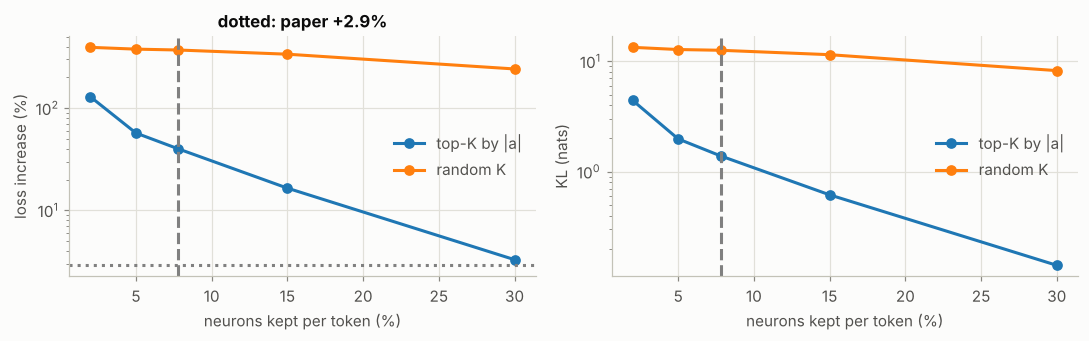

In [4]:
FRACS = [0.02, 0.05, 0.078, 0.15, 0.30]
curve = {"abs": [], "random": []}
for frac in FRACS:
    k = round(frac * F)
    for keep in curve:
        r = nl.loss_and_kl(model, EVAL, lambda: nl.sparsify(model, keep=keep, k=k, fill="zero"))
        curve[keep].append(dict(frac=frac, k=k, **r))
        print(f"남김 {frac:5.1%} (K={k:4d})  {keep:6s}: 손실 +{100 * r['rel']:6.1f}%   KL {r['kl']:6.2f}", flush=True)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for keep, lab in [("abs", "top-K by |a|"), ("random", "random K")]:
    ax[0].plot([100 * r["frac"] for r in curve[keep]], [100 * r["rel"] for r in curve[keep]], marker="o", label=lab)
    ax[1].plot([100 * r["frac"] for r in curve[keep]], [r["kl"] for r in curve[keep]], marker="o", label=lab)
for a in ax:
    a.axvline(7.8, ls="--", c="gray"); a.set_xlabel("neurons kept per token (%)"); a.legend()
ax[0].axhline(2.9, ls=":", c="gray"); ax[0].set(ylabel="loss increase (%)", yscale="log", title="dotted: paper +2.9%")
ax[1].set(ylabel="KL (nats)", yscale="log")
plt.tight_layout(); plt.show()

**읽는 법.**
- **옮겨 오는 것:** 센 뉴런만 남기는 것은 무작위보다 압도적으로 낫다. 모든 비율에서 손실 증가가 세 배(2%)에서 일흔 배 넘게(30%) 차이 난다. 모델이 쓰는 정보가 강한 활성에 몰려 있다는 주장의 **방향**은 이 모델에서도 성립한다.
- **옮겨 오지 않는 것:** 7.8%에서 손실 증가(+40%)는 논문의 +2.9%보다 열 배 넘게 크다. 이 모델에서 논문 수준에 가까워지려면 약 30%를 남겨야 한다. "7.8%면 충분하다"는 **숫자**는 이 모델로 옮겨 오지 않는다.
- 왜 다를까? 이 권은 답하지 못한다. 후보는 셋이다. (가) 모델 크기(0.6B vs 35B), (나) MoE(논문의 4,096개는 이미 router가 고른 전문가 안의 뉴런이다), (다) 데이터(백과사전 vs 웹 문서). 하나씩 떼어 보려면 다른 크기의 dense 모델과 작은 MoE 모델이 필요하다. 장부에 남긴다.

## 4. 무엇을 기준으로 "세다"고 하나

① Cell 04의 크기 대칭: up 행에 $c$를 곱하고 $d_i$를 $c$로 나누면 함수는 같은데 $|a_i|$는 $c$배가 된다. 그래서 $|a|$로 줄 세우는 것은 학습이 정한 크기 배분에 기댄다. 쓰기 크기 $|a_i|\,\lVert d_i\rVert$는 이 대칭에 대해 변하지 않는다.

**✍️ 예측 3.** 7.8%에서 (가) $|a|$ 기준 상위 $K$와 $|a|\,\lVert d_i\rVert$ 기준 상위 $K$는 평균 몇 %가 겹칠까? (나) 손실은 어느 기준이 낮을까? 대칭으로 보면 쓰기 기준이 더 '옳은' 기준 같은데, 실제로도 그럴까?

#### Cell 05 · |a| 기준 vs 쓰기 크기 기준

- **이번 셀의 질문:** 두 기준은 같은 뉴런을 고르나? 어느 쪽이 손실을 덜 늘리나?
- **출력에서 볼 것:** 층별 겹침의 평균과 최솟값, 두 기준의 손실과 KL.
- **해석 범위:** 약 2분. 겹침은 평가 조각 4개의 첫 위치를 뺀 token에서 잰다.

In [5]:
cap = {}
hs = [nl.layers(model)[l].mlp.down_proj.register_forward_pre_hook(lambda m, inp, l=l: cap.__setitem__(l, inp[0])) for l in range(L)]
with torch.inference_mode():
    model(EVAL[:4])
for h in hs:
    h.remove()
overlap = []
for l in range(L):
    a = cap[l][:, 1:].reshape(-1, F)
    dn = nl.layers(model)[l].mlp.down_proj.weight.norm(dim=0)
    m1 = torch.zeros_like(a, dtype=torch.bool).scatter_(-1, a.abs().topk(K78, -1).indices, True)
    m2 = torch.zeros_like(a, dtype=torch.bool).scatter_(-1, (a.abs() * dn).topk(K78, -1).indices, True)
    overlap.append(((m1 & m2).sum(-1).float() / K78).mean().item())
del cap
crit_res = {"|a|": curve["abs"][FRACS.index(0.078)],
            "|a|·‖d‖": nl.loss_and_kl(model, EVAL, lambda: nl.sparsify(model, keep="write", k=K78, fill="zero"))}
print(f"두 기준의 상위 K 겹침: 층 평균 {np.mean(overlap):.0%}, 가장 낮은 층 {np.min(overlap):.0%}")
for k, r in crit_res.items():
    print(f"  {k:8s} 기준: 손실 +{100 * r['rel']:.0f}%   KL {r['kl']:.2f}")

두 기준의 상위 K 겹침: 층 평균 88%, 가장 낮은 층 79%
  |a|      기준: 손실 +40%   KL 1.39
  |a|·‖d‖  기준: 손실 +53%   KL 1.84


**읽는 법.** 두 기준은 대부분 같은 뉴런을 고른다. 그런데 손실은 $|a|$ 기준이 더 낮다. 대칭만 보면 쓰기 크기가 더 원칙적인 기준이지만, 실제로 학습된 모델에서는 $|a|$가 더 잘 맞는다. 학습이 정한 크기 배분이 정보를 담고 있다는 뜻이다. 그 이유는 이 권에서 답하지 않는다. 이 쓰기 벡터들이 뒤에서 RMSNorm을 거친다는 점, 그리고 뒤 층들이 어느 방향을 읽는지가 쓰기 크기만으로는 정해지지 않는다는 점이 후보다. 남는 교훈은 이것이다. **원칙적으로 옳아 보이는 기준과 실제로 잘 맞는 기준은 재 봐야 안다.** 논문이 $|a|$를 쓴 것은 이 모델에서도 나쁜 선택이 아니었다.

## 5. 분위수 띠: 약한 활성은 버려도 되나

**✍️ 예측 4.** 뉴런마다 활성이 p10–p90 사이면 평균으로 바꾼다. 이때 token마다 남는 뉴런은 평균 몇 %일까(대략 20%쯤일까)? 손실은 몇 % 늘까? p3–p97 사이를 바꾸면? 논문은 이런 띠 대체가 "원래 모델에 가깝다"고 했다.

#### Cell 06 · 분위수 띠 대체

- **이번 셀의 질문:** 약한 활성을 평균으로 바꾸면 손실이 얼마나 느나?
- **출력에서 볼 것:** 두 띠의 남는 비율, 손실 증가, KL.
- **해석 범위:** 약 2분. 분위수와 평균은 첫 위치를 뺀 보정(`STATS`)으로 잰다.

In [6]:
band_res = {}
for band in [("p10", "p90"), ("p3", "p97")]:
    kept = []
    r = nl.loss_and_kl(model, EVAL, lambda: nl.sparsify(model, keep="band", band=band, fill="mean", stats=STATS, record=kept))
    band_res[f"{band[0]}–{band[1]}"] = dict(kept=float(np.mean(kept)), **r)
    print(f"{band[0]}–{band[1]} 사이를 평균으로: 남는 비율 {np.mean(kept):.1%}   손실 +{100 * r['rel']:.0f}%   KL {r['kl']:.2f}")

p10–p90 사이를 평균으로: 남는 비율 18.6%   손실 +17%   KL 0.65


p3–p97 사이를 평균으로: 남는 비율 5.3%   손실 +81%   KL 2.85


**읽는 법.** 남는 비율이 예측보다 다를 수 있다. 분위수는 뉴런마다 따로 잰 것이라, token 하나에서 몇 개가 띠 바깥에 있는지는 뉴런들이 얼마나 함께 켜지는지에 달려 있다. 손실 증가를 Cell 04의 top-K 곡선과 **남는 비율이 같은 지점**에서 비교한다. 이 모델에서는 띠 대체가 top-K보다 조금 나쁘다. p10–p90 띠는 18.6%를 남기고 +17%인데, top-K는 15%만 남겨도 +16.5%다. p3–p97 띠는 5.3%를 남기고 +81%인데, top-K는 5%에서 +57%다. "강한 활성"을 뉴런마다의 분위수로 정의하면 token 안의 순위로 정의할 때보다 정보를 조금 더 버린다. 어느 쪽이든 논문의 "원래 모델에 가깝다"는 이 모델에서 성립하지 않는다.

## 6. "작다"는 무엇과 비교해서인가

손실 +2.9%를 "작다"고 말하려면 비교 대상이 있어야 한다. 이 권에서 잰 것으로 기준을 세 개 만든다.

#### Cell 07 · 기준 세 개로 다시 읽기

- **이번 셀의 질문:** 같은 손실 증가를 어떤 눈금에서 읽는가?
- **출력에서 볼 것:** 7.8%와 30%에서 top-K, 무작위, 그리고 손실 증가를 perplexity 배율로 바꾼 값.
- **해석 범위:** [대수] perplexity는 $e^{\text{손실}}$이라 손실이 $\Delta$ nats 늘면 perplexity는 $e^{\Delta}$배가 된다. 손실 % 증가와 perplexity 배율은 다른 눈금이다.

In [7]:
rows = []
for frac in [0.078, 0.30]:
    i = FRACS.index(frac)
    for keep in ["abs", "random"]:
        r = curve[keep][i]
        rows.append((f"{frac:.1%} {keep}", r["rel"], np.exp(r["loss"] - r["loss_base"]), r["kl"]))
paper_delta = 0.029 * BASE   # 논문의 +2.9%를 이 모델의 원래 손실에 적용했을 때
rows.append(("논문 +2.9%를 이 모델에 대입", 0.029, np.exp(paper_delta), float("nan")))
print(f"{'조건':28s} {'손실 증가':>8s} {'perplexity 배율':>14s} {'KL':>6s}")
for name, rel, ppl, kl in rows:
    print(f"{name:28s} {rel:8.1%} {ppl:14.2f} {kl:6.2f}")

조건                              손실 증가  perplexity 배율     KL
7.8% abs                        40.0%           3.88   1.39
7.8% random                    371.4%      293081.44  12.61
30.0% abs                        3.3%           1.12   0.14
30.0% random                   242.3%        3690.32   8.25
논문 +2.9%를 이 모델에 대입               2.9%           1.10    nan


**읽는 법.** 기준 하나: **무작위**. 같은 수를 무작위로 남기면 모델이 사실상 무너진다. 그 눈금에서는 top-K가 아주 작아 보인다. 기준 둘: **원래 모델**. perplexity 배율로 보면 7.8% top-K는 이 모델을 크게 망가뜨린다. 기준 셋: **논문 숫자**. +2.9%는 이 모델에서 perplexity 약 1.1배다. 같은 수준이 되려면 30% 가까이 남겨야 한다.

논문은 벤치마크에서도 원래 모델과 비교했고, 가벼운 미세조정으로 차이를 메웠다고 보고한다. 이 권은 손실과 KL만 쟀다. 벤치마크는 이 모델 크기에서는 점수가 낮아 비교가 흐리다(구멍 장부).

## 주장 장부

In [8]:
abs78, rnd78, abs30 = curve["abs"][FRACS.index(0.078)], curve["random"][FRACS.index(0.078)], curve["abs"][FRACS.index(0.30)]
ledger = [
    ("센 뉴런만 남기는 것이 같은 수의 무작위보다 훨씬 낫다", "유지 (이 모델로 옮겨 옴)", f"Cell 04: 7.8%에서 +{100 * abs78['rel']:.0f}% vs +{100 * rnd78['rel']:.0f}%"),
    ("층마다 7.8%만 남기면 손실 +3% 안팎이다", "이 모델에서 기각", f"Cell 04: +{100 * abs78['rel']:.0f}%. 30%에서 +{100 * abs30['rel']:.1f}%"),
    ("평균 대체가 0 대체보다 낫다", "평균을 어디서 쟀는지에 달림", f"Cell 03: 첫 위치 포함 +{100 * fill_res['평균 (첫 위치 포함해 잼)']['rel']:.0f}%, 뺌 +{100 * fill_res['평균 (첫 위치 빼고 잼)']['rel']:.0f}%, 0 +{100 * fill_res['0으로']['rel']:.0f}%"),
    ("크기 대칭 때문에 |a| 기준은 나쁜 기준이다", "기각", f"Cell 05: 겹침 {np.mean(overlap):.0%}, |a| 기준이 손실이 더 낮다"),
    ("약한 활성(p10–p90)을 평균으로 바꿔도 원래 모델에 가깝다", "이 모델에서 기각" if band_res["p10–p90"]["rel"] > 0.05 else "유지", f"Cell 06: +{100 * band_res['p10–p90']['rel']:.0f}% (남는 비율 {band_res['p10–p90']['kept']:.0%})"),
    ("차이의 원인이 모델 크기, MoE, 데이터 중 무엇인가", "모름", "다른 크기의 dense 모델과 작은 MoE가 필요"),
]
for claim, status, ev in ledger:
    print(f"[{status}] {claim}\n    근거: {ev}")
nl.save_results("03_sparsity", dict(model=nl.DEFAULT_MODEL, eval_tokens=int(EVAL.numel()), base_loss=BASE, K78=K78,
                                    first_vs_rest=dict(first=first, rest=rest), fill=fill_res, curve=curve,
                                    criterion=dict(overlap_mean=float(np.mean(overlap)), overlap_min=float(np.min(overlap)), results=crit_res),
                                    band=band_res, ledger=ledger))
print("\nresults/03_sparsity.json 저장")

[유지 (이 모델로 옮겨 옴)] 센 뉴런만 남기는 것이 같은 수의 무작위보다 훨씬 낫다
    근거: Cell 04: 7.8%에서 +40% vs +371%
[이 모델에서 기각] 층마다 7.8%만 남기면 손실 +3% 안팎이다
    근거: Cell 04: +40%. 30%에서 +3.3%
[평균을 어디서 쟀는지에 달림] 평균 대체가 0 대체보다 낫다
    근거: Cell 03: 첫 위치 포함 +154%, 뺌 +29%, 0 +40%
[기각] 크기 대칭 때문에 |a| 기준은 나쁜 기준이다
    근거: Cell 05: 겹침 88%, |a| 기준이 손실이 더 낮다
[이 모델에서 기각] 약한 활성(p10–p90)을 평균으로 바꿔도 원래 모델에 가깝다
    근거: Cell 06: +17% (남는 비율 19%)
[모름] 차이의 원인이 모델 크기, MoE, 데이터 중 무엇인가
    근거: 다른 크기의 dense 모델과 작은 MoE가 필요

results/03_sparsity.json 저장


## 구멍 장부

| 건너뛴 것 | 지금 알아 둘 한 줄 | 다시 나오는 곳 |
|---|---|---|
| attention sink | 많은 모델이 첫 위치에 attention을 몰아 두고, 그 위치의 activation이 유난히 크거나 작다 | ⑤에서 필요하면 |
| 논문의 평균은 어디서 쟀나 | 보고서와 원문에서 확인할 일 | 다음에 논문을 읽을 때 |
| MoE의 router weight | 논문의 활성은 $a\cdot w_{\text{router}}$이다. 전문가 선택이 이미 한 번의 희소화다 | 정의만 |
| 벤치마크와 미세조정 회복 | 논문은 ARC, HellaSwag 등에서 비교했고, 가벼운 미세조정으로 차이를 메웠다 | 이 모델 크기에서는 비교가 흐려 건너뜀 |
| 모델 크기의 효과 | 같은 계열의 더 큰 dense 모델(예: Qwen3-1.7B, 4B)로 곡선을 다시 그리면 떼어 볼 수 있다 | GPU가 있을 때 |
| Q3(이중 음수)가 상위 $K$에서 차지하는 몫 | ① Cell 03의 질문을 웹 문서에서 다시 재는 일 | ④ |